# Лабораторная работа № 2
## Сегментация изображений с помощью U-Net

**Цель:** построить U-Net для семантической сегментации, обучить её на наборе CARLA и повторить основные этапы на другом наборе изображений.

## 1. Библиотеки и данные

В работе использую CARLA и Penn-Fudan. Первый набор содержит изображения и маски дорожных сцен; второй — фотографии людей и их маски. Для Penn-Fudan выделяю два класса: фон и человек.

Источники: [CARLA](https://github.com/Rhythm-Adhikari1/U-Net/tree/072afa362ab567ceb8c151b18b00e05ac632bf26/data), [Penn-Fudan](https://github.com/swallan/PennFudanPed/tree/ec1d4583fb436b14e2062587c8b28a5018668a5e). Данные подготавливаются командой `python prepare_pennfudan.py`.

In [1]:
import os
import csv
import json
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import tensorflow as tf
from tensorflow.keras import layers

%matplotlib inline

tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.keras.utils.set_random_seed(42)

IMAGE_SIZE = (96, 128)
BATCH_SIZE = 8
EPOCHS = 40
RETRAIN = False  # True — обучить модели заново; False — загрузить сохранённые модели.
print("TensorFlow:", tf.__version__)

CARLA_CLASSES = ["Unlabeled", "Building", "Fence", "Other", "Pedestrian", "Pole",
                 "RoadLine", "Road", "Sidewalk", "Vegetation", "Vehicle", "Wall",
                 "TrafficSign", "Sky", "Ground", "Bridge", "RailTrack", "GuardRail",
                 "TrafficLight", "Static", "Dynamic", "Water", "Terrain"]
PERSON_CLASSES = ["Фон", "Человек"]

TensorFlow: 2.18.1


### 1.1. Подготовка и разбиение

В CARLA находятся 1060 изображений с масками для 23 классов. При разбиении соседние номера кадров объединены в группы. В Penn-Fudan — 170 изображений с готовыми масками; все номера людей в маске преобразованы в один класс. Данные разделены на обучение, валидацию и тест; соответствующие изображения и маски лежат в папках `images/train`, `images/val`, `images/test` и `masks/train`, `masks/val`, `masks/test`.

In [2]:
def load_split(name):
    root = Path("data") / name
    result = {}
    for part in ("train", "val", "test"):
        images = {p.stem: p for p in (root / "images" / part).glob("*.png")}
        masks = {p.stem: p for p in (root / "masks" / part).glob("*.png")}
        if not images or images.keys() != masks.keys():
            raise ValueError(f"Проверьте данные {name}/{part}: сначала выполните python prepare_pennfudan.py")
        result[part] = [(images[key], masks[key]) for key in sorted(images)]
    return result

carla_split = load_split("carla")
person_split = load_split("pennfudan")
for name, split in [("CARLA", carla_split), ("Penn-Fudan", person_split)]:
    print(name, {part: len(pairs) for part, pairs in split.items()})
    filenames = [{image.name for image, _ in split[part]} for part in ("train", "val", "test")]
    assert not (filenames[0] & filenames[1] or filenames[0] & filenames[2] or filenames[1] & filenames[2])

CARLA {'train': 848, 'val': 106, 'test': 106}
Penn-Fudan {'train': 136, 'val': 17, 'test': 17}


### 1.2. Предобработка изображений и масок

OpenCV приводит изображение к размеру 96×128, переводит его в RGB и нормализует пиксели. Маска изменяется методом nearest neighbor: так сохраняются номера классов. В масках CARLA номер хранится в красном канале, в Penn-Fudan — в одном канале.

In [3]:
def read_pair(image_path, mask_path, n_classes):
    image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    mask = cv2.imread(str(mask_path), cv2.IMREAD_UNCHANGED)
    if image is None or mask is None:
        raise ValueError(f"Не удалось прочитать {image_path} или {mask_path}")
    if image.shape[:2] != mask.shape[:2]:
        raise ValueError("Размеры изображения и маски не совпадают")
    if mask.ndim == 3:
        mask = mask[..., 2]  # красный канал CARLA при чтении OpenCV
    if mask.min() < 0 or mask.max() >= n_classes:
        raise ValueError("Неизвестный номер класса в маске")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (IMAGE_SIZE[1], IMAGE_SIZE[0]), interpolation=cv2.INTER_AREA)
    mask = cv2.resize(mask, (IMAGE_SIZE[1], IMAGE_SIZE[0]), interpolation=cv2.INTER_NEAREST)
    return image.astype(np.float32) / 255.0, mask.astype(np.int32)[..., None]


def load_arrays(pairs, n_classes):
    items = [read_pair(image, mask, n_classes) for image, mask in pairs]
    return np.stack([x for x, _ in items]), np.stack([y for _, y in items])


def make_dataset(images, masks, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((images, masks))
    if training:
        dataset = dataset.shuffle(len(images), seed=42)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    return dataset.batch(BATCH_SIZE).with_options(options).prefetch(1)

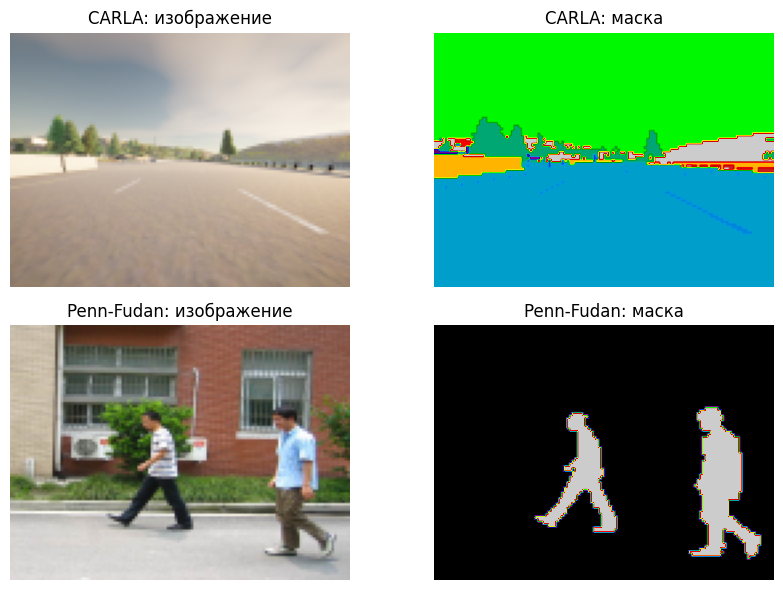

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for row, (name, split, classes) in enumerate([
    ("CARLA", carla_split, 23), ("Penn-Fudan", person_split, 2)]):
    image, mask = read_pair(*split["train"][0], classes)
    axes[row, 0].imshow(image)
    axes[row, 1].imshow(mask[..., 0], cmap="nipy_spectral", vmin=0, vmax=classes - 1)
    axes[row, 0].set_title(name + ": изображение")
    axes[row, 1].set_title(name + ": маска")
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Построение U-Net

Сеть состоит из пяти блоков сжатия и четырёх блоков восстановления. Skip connections передают признаки из encoder в decoder. Последний слой выдаёт по одному каналу на каждый класс.

In [5]:
def conv_block(inputs, n_filters=32, dropout_prob=0, max_pooling=True):
    conv = layers.Conv2D(n_filters, 3, activation="relu", padding="same", kernel_initializer="he_normal")(inputs)
    conv = layers.Conv2D(n_filters, 3, activation="relu", padding="same", kernel_initializer="he_normal")(conv)
    if dropout_prob > 0:
        conv = layers.Dropout(dropout_prob)(conv)
    next_layer = layers.MaxPooling2D(2)(conv) if max_pooling else conv
    return next_layer, conv


def upsampling_block(expansive_input, contractive_input, n_filters=32):
    up = layers.Conv2DTranspose(n_filters, 3, strides=2, padding="same")(expansive_input)
    merge = layers.concatenate([up, contractive_input], axis=3)
    conv = layers.Conv2D(n_filters, 3, activation="relu", padding="same", kernel_initializer="he_normal")(merge)
    conv = layers.Conv2D(n_filters, 3, activation="relu", padding="same", kernel_initializer="he_normal")(conv)
    return conv


def unet_model(input_size=(96, 128, 3), n_filters=32, n_classes=23):
    inputs = layers.Input(input_size)
    c1 = conv_block(inputs, n_filters)
    c2 = conv_block(c1[0], n_filters * 2)
    c3 = conv_block(c2[0], n_filters * 4)
    c4 = conv_block(c3[0], n_filters * 8, dropout_prob=0.3)
    c5 = conv_block(c4[0], n_filters * 16, dropout_prob=0.3, max_pooling=False)
    u6 = upsampling_block(c5[0], c4[1], n_filters * 8)
    u7 = upsampling_block(u6, c3[1], n_filters * 4)
    u8 = upsampling_block(u7, c2[1], n_filters * 2)
    u9 = upsampling_block(u8, c1[1], n_filters)
    conv = layers.Conv2D(n_filters, 3, activation="relu", padding="same", kernel_initializer="he_normal")(u9)
    outputs = layers.Conv2D(n_classes, 1, padding="same")(conv)
    return tf.keras.Model(inputs, outputs, name="unet")

model = unet_model()
model.summary()
print("Размер выхода:", model.output_shape)
del model

Model: "unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 96, 128,   │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 96, 128,   │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 96, 128,   │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 48, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 48, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 48, 64,    │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 24, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 24, 32,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 24, 32,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 12, 16,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 12, 16,    │    295,168 │ max_pooling2d_2[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 12, 16,    │    590,080 │ conv2d_6[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 12, 16,    │          0 │ conv2d_7[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 6, 8, 256) │          0 │ dropout[0][0]     │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 6, 8, 512) │  1,180,160 │ max_pooling2d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 6, 8, 512) │  2,359,808 │ conv2d_8[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 6, 8, 512) │          0 │ conv2d_9[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 12, 16,    │  1,179,904 │ dropout_1[0][0] 

 Total params: 8,640,471 (32.96 MB)

 Trainable params: 8,640,471 (32.96 MB)

 Non-trainable params: 0 (0.00 B)

Размер выхода: (None, 96, 128, 23)


## 3. Обучение на CARLA

Использую Adam, 40 эпох, batch size 8 и sparse categorical crossentropy. Веса классов рассчитываются по обучающим маскам, чтобы уменьшить влияние дисбаланса. Модель сохраняется по лучшему mean IoU на валидации.

In [6]:
def class_weights(masks, n_classes):
    counts = np.bincount(masks.ravel(), minlength=n_classes).astype(np.float64)
    frequencies = counts / counts.sum()
    weights = np.zeros(n_classes, dtype=np.float64)
    present = counts > 0
    weights[present] = 1 / np.sqrt(np.maximum(frequencies[present], 0.002))
    return (weights / np.dot(weights, frequencies)).astype(np.float32)


@tf.keras.utils.register_keras_serializable(package="Lab2")
class WeightedCrossEntropy(tf.keras.losses.Loss):
    def __init__(self, weights, name="weighted_cross_entropy", **kwargs):
        super().__init__(name=name, **kwargs)
        self.weights = [float(value) for value in weights]

    def call(self, y_true, y_pred):
        labels = tf.cast(tf.squeeze(y_true, axis=-1), tf.int32)
        loss = tf.nn.sparse_softmax_cross_entropy_with_logits(labels=labels, logits=y_pred)
        return loss * tf.gather(tf.constant(self.weights, tf.float32), labels)

    def get_config(self):
        return {**super().get_config(), "weights": self.weights}


def read_history(path):
    with open(path, newline="") as file:
        rows = list(csv.DictReader(file))
    return {key: [float(row[key]) for row in rows] for key in rows[0] if key != "epoch"}


def plot_history(history, save_path):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    for ax, metric in zip(axes, ("loss", "accuracy")):
        ax.plot(history[metric], label="train")
        ax.plot(history["val_" + metric], label="validation")
        ax.set(xlabel="Эпоха", title=metric)
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    fig.savefig(save_path, dpi=140)
    plt.show()

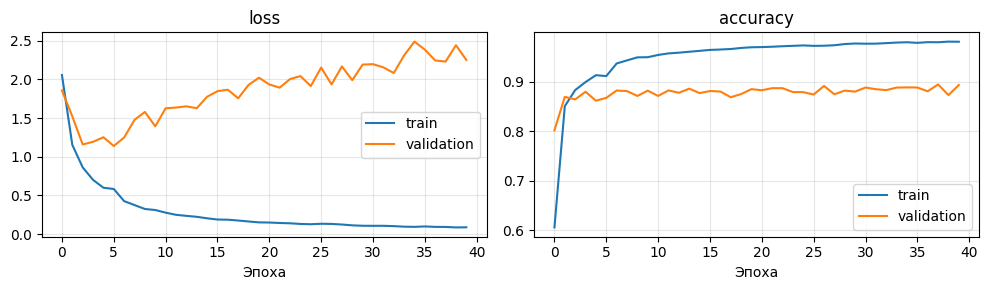

In [7]:
if RETRAIN:
    tf.keras.utils.set_random_seed(42)
    carla_x, carla_y = load_arrays(carla_split["train"], 23)
    carla_val_x, carla_val_y = load_arrays(carla_split["val"], 23)
    weights = class_weights(carla_y, 23)
    carla_model = unet_model(n_classes=23)
    carla_model.compile(
        optimizer="adam", loss=WeightedCrossEntropy(weights),
        weighted_metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
                          tf.keras.metrics.IoU(num_classes=23, target_class_ids=list(range(23)),
                                               sparse_y_pred=False, name="mean_iou")])
    history = carla_model.fit(
        make_dataset(carla_x, carla_y, training=True),
        validation_data=make_dataset(carla_val_x, carla_val_y), epochs=EPOCHS,
        callbacks=[tf.keras.callbacks.ModelCheckpoint("results/carla_unet_best.keras", monitor="val_mean_iou", mode="max", save_best_only=True),
                   tf.keras.callbacks.CSVLogger("results/carla_unet_history.csv")], verbose=2)
    carla_model = tf.keras.models.load_model("results/carla_unet_best.keras", compile=False)
    carla_model.save("results/carla_unet.keras")
else:
    carla_model = tf.keras.models.load_model("results/carla_unet.keras", compile=False)
carla_history = read_history("results/carla_unet_history.csv")
plot_history(carla_history, "results/carla_unet_history.png")

### 3.1. Оценка и предсказания

Accuracy показывает долю правильных пикселей. IoU класса — отношение пересечения истинной и предсказанной областей к их объединению. Mean IoU усредняет IoU по классам, которые присутствуют в истинных или предсказанных масках.

In [8]:
def predict_and_score(model, pairs, n_classes):
    images, masks = load_arrays(pairs, n_classes)
    predictions = np.argmax(model.predict(images, batch_size=BATCH_SIZE, verbose=0), axis=-1)
    truth = masks[..., 0]
    matrix = np.bincount((n_classes * truth + predictions).ravel(),
                         minlength=n_classes ** 2).reshape(n_classes, n_classes)
    intersection = np.diag(matrix)
    union = matrix.sum(axis=0) + matrix.sum(axis=1) - intersection
    iou = np.divide(intersection, union, out=np.full(n_classes, np.nan), where=union > 0)
    return images, truth, predictions, matrix.trace() / matrix.sum(), iou


def label_colors(n_classes):
    colors = np.zeros((n_classes, 3), dtype=np.uint8)
    for label in range(n_classes):
        value = label
        for bit in range(8):
            for channel in range(3):
                colors[label, channel] |= ((value >> channel) & 1) << (7 - bit)
            value >>= 3
    return colors


def show_predictions(images, masks, predictions, class_names, save_path, count=3):
    indexes = np.linspace(0, len(images) - 1, min(count, len(images)), dtype=int)
    colors = label_colors(len(class_names))
    fig, axes = plt.subplots(len(indexes), 3, figsize=(10, 3 * len(indexes)), squeeze=False)
    for row, index in enumerate(indexes):
        axes[row, 0].imshow(images[index])
        axes[row, 1].imshow(colors[masks[index]])
        axes[row, 2].imshow(colors[predictions[index]])
        for ax, title in zip(axes[row], ["Изображение", "Настоящая маска", "Предсказание"]):
            ax.set_title(title)
            ax.axis("off")
    present = np.union1d(np.unique(masks[indexes]), np.unique(predictions[indexes]))
    handles = [Patch(color=colors[i] / 255, label=f"{i}: {class_names[i]}") for i in present]
    fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=8)
    plt.tight_layout(rect=(0, 0.14 if len(handles) > 4 else 0.05, 1, 1))
    fig.subplots_adjust(hspace=0.35)
    fig.savefig(save_path, dpi=140)
    plt.show()


def save_scores(path, accuracy, iou, test_images):
    scores = {"test_images": test_images, "accuracy": float(accuracy),
              "mean_iou": float(np.nanmean(iou)),
              "iou_per_class": [float(value) if np.isfinite(value) else None for value in iou]}
    Path(path).write_text(json.dumps(scores, indent=2), encoding="utf-8")

CARLA: accuracy = 0.886; mean IoU = 0.247


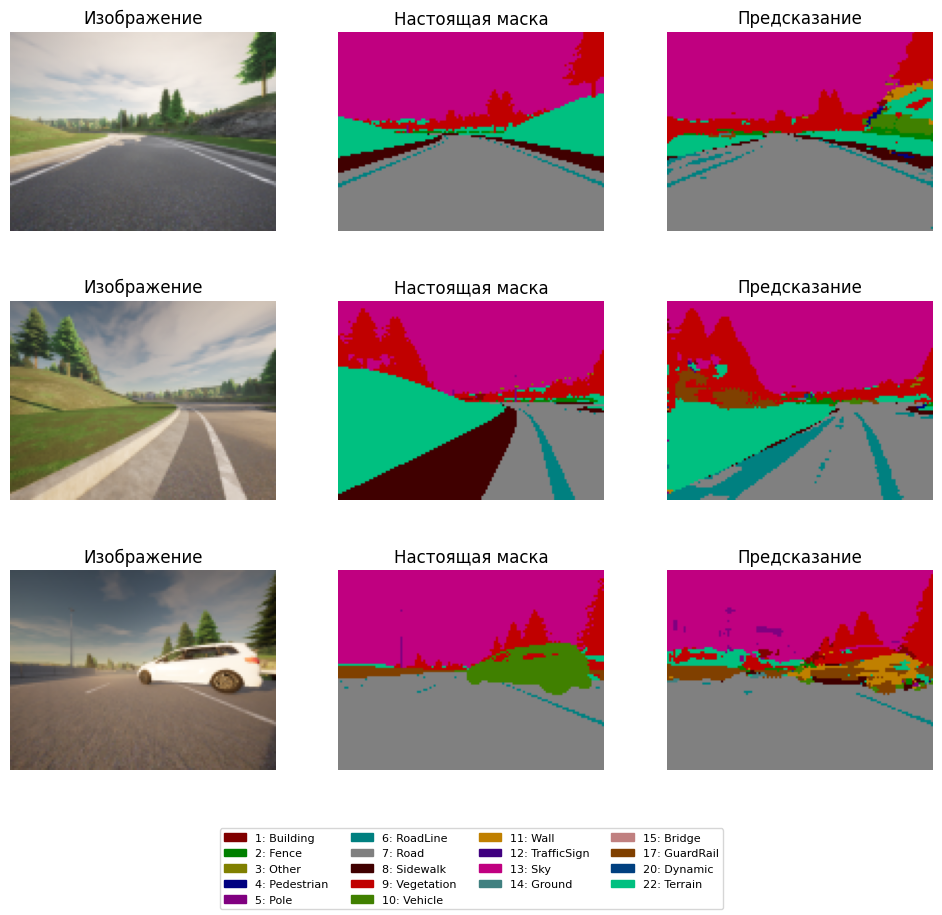

In [9]:
carla_images, carla_masks, carla_pred, carla_accuracy, carla_iou = predict_and_score(
    carla_model, carla_split["test"], 23)
print(f"CARLA: accuracy = {carla_accuracy:.3f}; mean IoU = {np.nanmean(carla_iou):.3f}")
show_predictions(carla_images, carla_masks, carla_pred, CARLA_CLASSES, "results/carla_unet_predictions.png")
save_scores("results/carla_unet_metrics.json", carla_accuracy, carla_iou, len(carla_images))

## 4. Второй набор: сегментация людей

Для второй задачи выбран набор Penn-Fudan. На масках 0 обозначает фон, 1 — человека. Для каждой фотографии используется соответствующая пиксельная маска. Разбиение: 136 изображений для обучения, 17 для валидации и 17 для тестирования. Повторяю предобработку и обучение той же U-Net, изменив число выходных классов с 23 на 2.

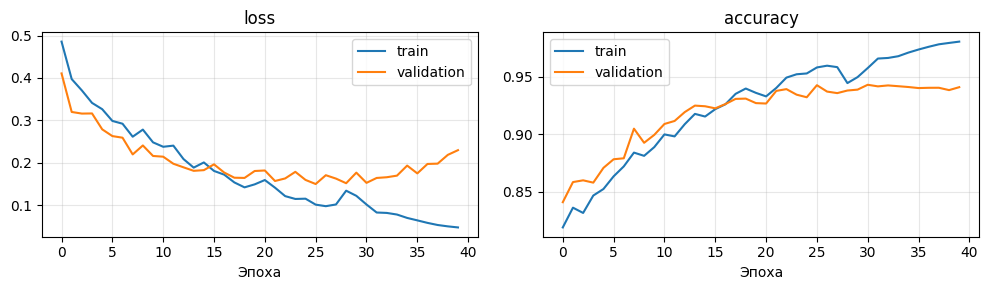

In [10]:
if RETRAIN:
    tf.keras.utils.set_random_seed(42)
    person_x, person_y = load_arrays(person_split["train"], 2)
    person_val_x, person_val_y = load_arrays(person_split["val"], 2)
    person_model = unet_model(n_classes=2)
    person_model.compile(
        optimizer="adam", loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        weighted_metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")])
    person_model.fit(
        make_dataset(person_x, person_y, training=True),
        validation_data=make_dataset(person_val_x, person_val_y), epochs=EPOCHS,
        callbacks=[tf.keras.callbacks.ModelCheckpoint("results/penn32_best.keras", monitor="val_loss", save_best_only=True),
                   tf.keras.callbacks.CSVLogger("results/penn32_history.csv")], verbose=2)
    person_model = tf.keras.models.load_model("results/penn32_best.keras", compile=False)
    person_model.save("results/penn32.keras")
else:
    person_model = tf.keras.models.load_model("results/penn32.keras", compile=False)
person_history = read_history("results/penn32_history.csv")
plot_history(person_history, "results/penn32_history.png")

Penn-Fudan: accuracy = 0.930; mean IoU = 0.776
IoU класса 'человек' = 0.632


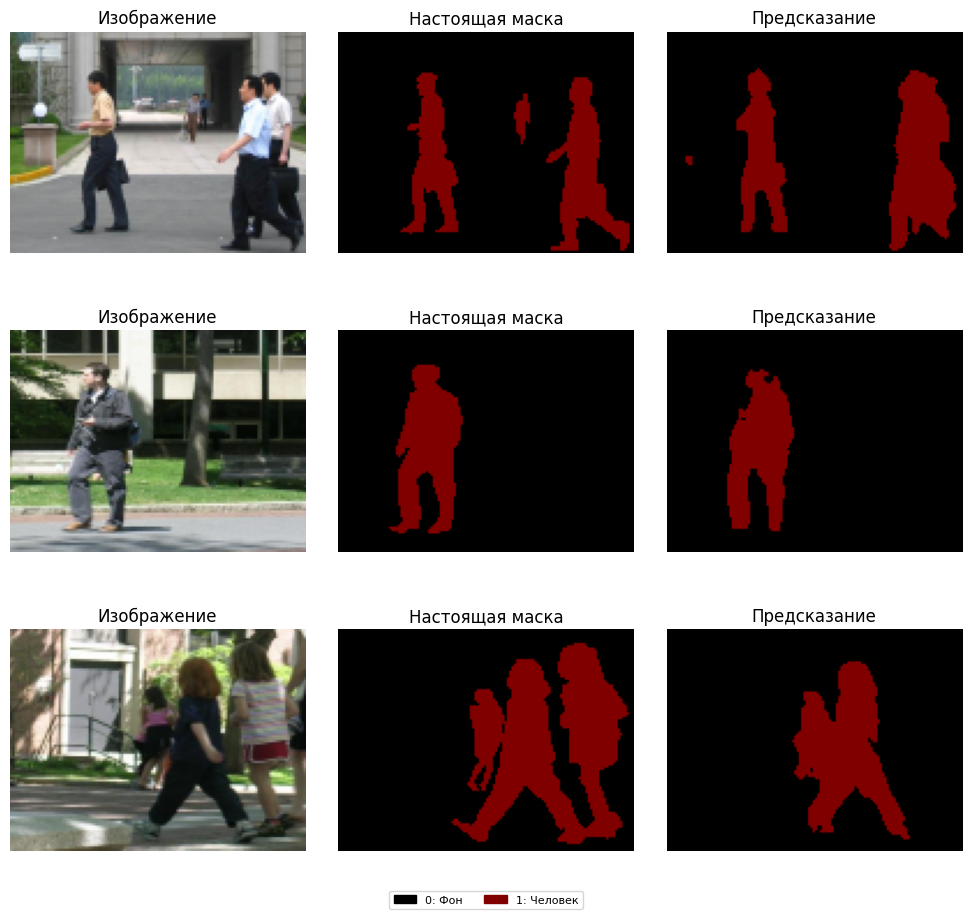

In [11]:
person_images, person_masks, person_pred, person_accuracy, person_iou = predict_and_score(
    person_model, person_split["test"], 2)
print(f"Penn-Fudan: accuracy = {person_accuracy:.3f}; mean IoU = {np.nanmean(person_iou):.3f}")
print(f"IoU класса 'человек' = {person_iou[1]:.3f}")
show_predictions(person_images, person_masks, person_pred, PERSON_CLASSES, "results/penn32_predictions.png")
save_scores("results/penn32_metrics.json", person_accuracy, person_iou, len(person_images))

## 5. Вывод

Построена U-Net и выполнена сегментация двух наборов изображений. Для CARLA сеть предсказывает 23 класса, для Penn-Fudan — человека и фон. На результат влияют различия между наборами, размер тестовой выборки и качество границ объектов. Численные оценки и примеры масок приведены выше.

## 6. Собственные фотографии

Для дополнительной проверки применяю обученные модели к собственным фотографиям. Эталонных масок для них нет, поэтому ниже показаны только предсказания. На последней колонке белым выделен класс «человек».

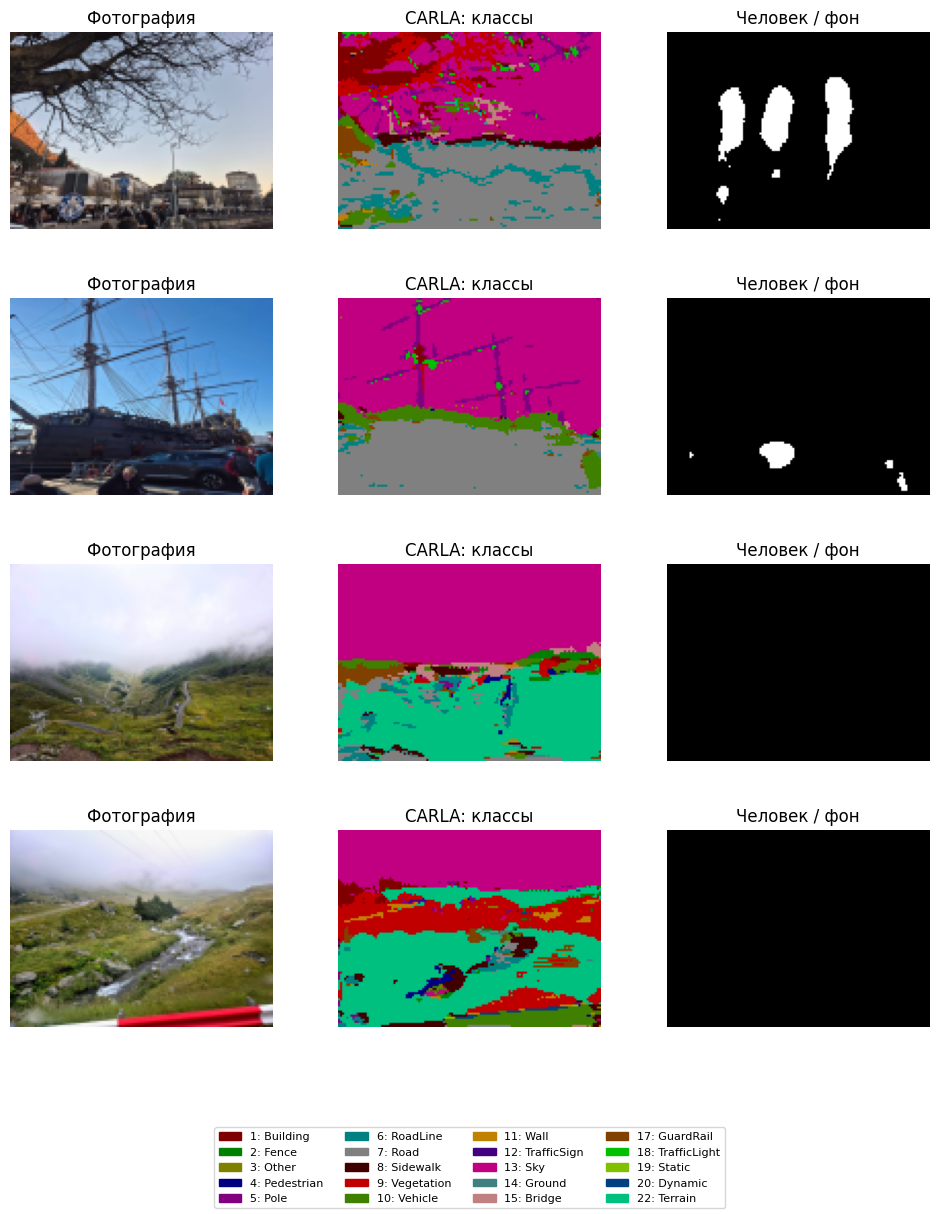

In [12]:
photo_paths = [Path("photos/city.jpg"), Path("photos/harbor.jpg"),
               Path("photos/mountain_road.jpg"), Path("photos/road_and_stream.jpg")]
photos = []
for path in photo_paths:
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    photos.append(cv2.resize(image, (IMAGE_SIZE[1], IMAGE_SIZE[0]), interpolation=cv2.INTER_AREA) / 255.0)
photos = np.asarray(photos, dtype=np.float32)
carla_photos = np.argmax(carla_model.predict(photos, verbose=0), axis=-1)
people_photos = np.argmax(person_model.predict(photos, verbose=0), axis=-1)
colors = label_colors(23)
fig, axes = plt.subplots(len(photos), 3, figsize=(10, 12))
for i in range(len(photos)):
    axes[i, 0].imshow(photos[i])
    axes[i, 1].imshow(colors[carla_photos[i]])
    axes[i, 2].imshow(people_photos[i], cmap="gray", vmin=0, vmax=1)
    for ax, title in zip(axes[i], ["Фотография", "CARLA: классы", "Человек / фон"]):
        ax.set_title(title)
        ax.axis("off")
present = np.unique(carla_photos)
handles = [Patch(color=colors[i] / 255, label=f"{i}: {CARLA_CLASSES[i]}") for i in present]
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=8)
plt.tight_layout(rect=(0, 0.14, 1, 1))
fig.subplots_adjust(hspace=0.35)
fig.savefig("results/own_predictions.png", dpi=140)
plt.show()